In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from sklearn.datasets import fetch_california_housing

# Download California Housing dataset
housing = fetch_california_housing(as_frame=True)

# Store dataset in a DataFrame
dataset = housing.frame.copy()

print("Dataset downloaded and loaded successfully!")

Dataset downloaded and loaded successfully!


In [4]:
dataset.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
dataset.tail()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


In [6]:
print("Total Rows:", dataset.shape[0])
print("Total Columns:", dataset.shape[1])

Total Rows: 20640
Total Columns: 9


In [7]:
print("Dataset Columns:")

for column in dataset.columns:
    print(column)

Dataset Columns:
MedInc
HouseAge
AveRooms
AveBedrms
Population
AveOccup
Latitude
Longitude
MedHouseVal


In [8]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [9]:
print("Missing Values:")

print(dataset.isnull().sum())

print("\nTotal Missing Values:", dataset.isnull().sum().sum())

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total Missing Values: 0


In [10]:
import os

os.makedirs("data", exist_ok=True)

dataset.to_csv("data/california_housing.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [11]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [12]:
dataset.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


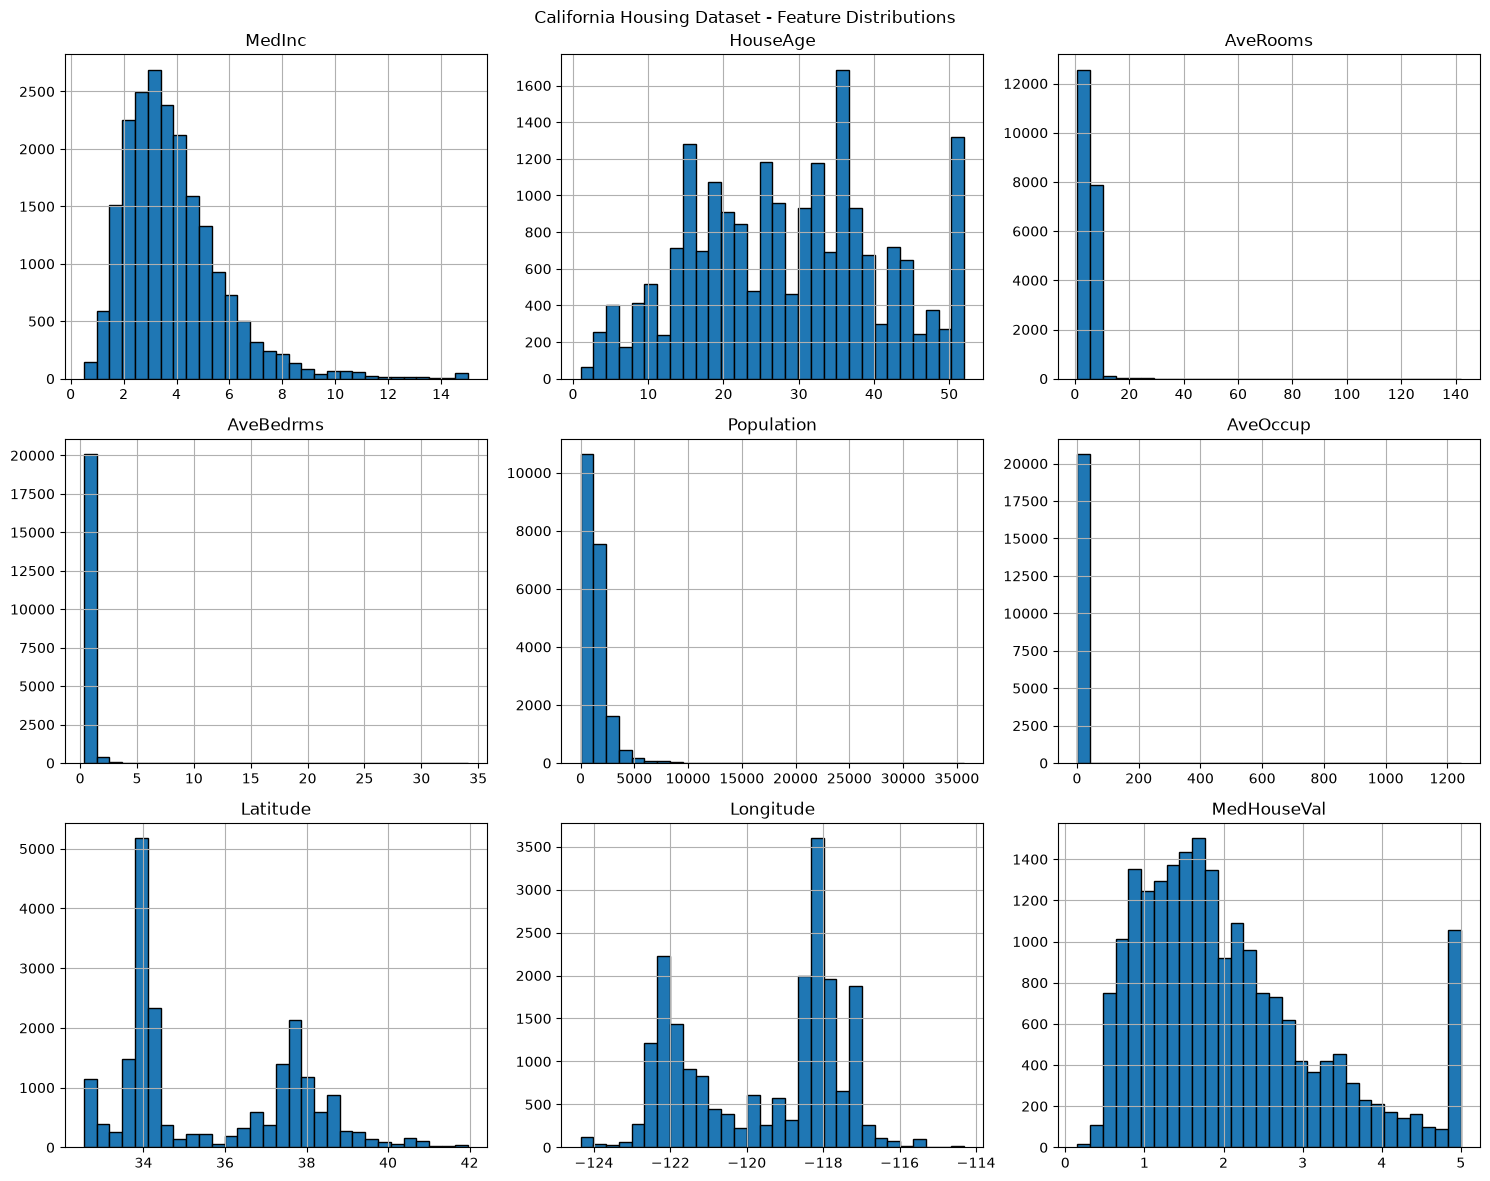

In [13]:
dataset.hist(figsize=(15, 12), bins=30, edgecolor="black")

plt.suptitle("California Housing Dataset - Feature Distributions")

plt.tight_layout()
plt.show()

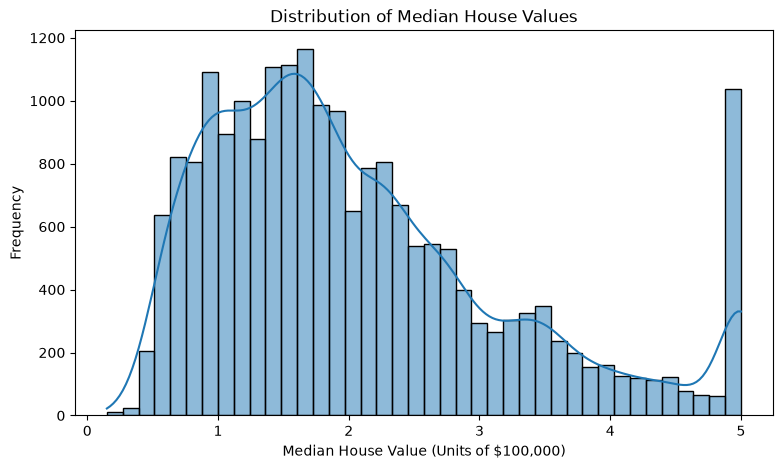

In [14]:
plt.figure(figsize=(9, 5))

sns.histplot(dataset["MedHouseVal"], bins=40, kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (Units of $100,000)")
plt.ylabel("Frequency")

plt.show()

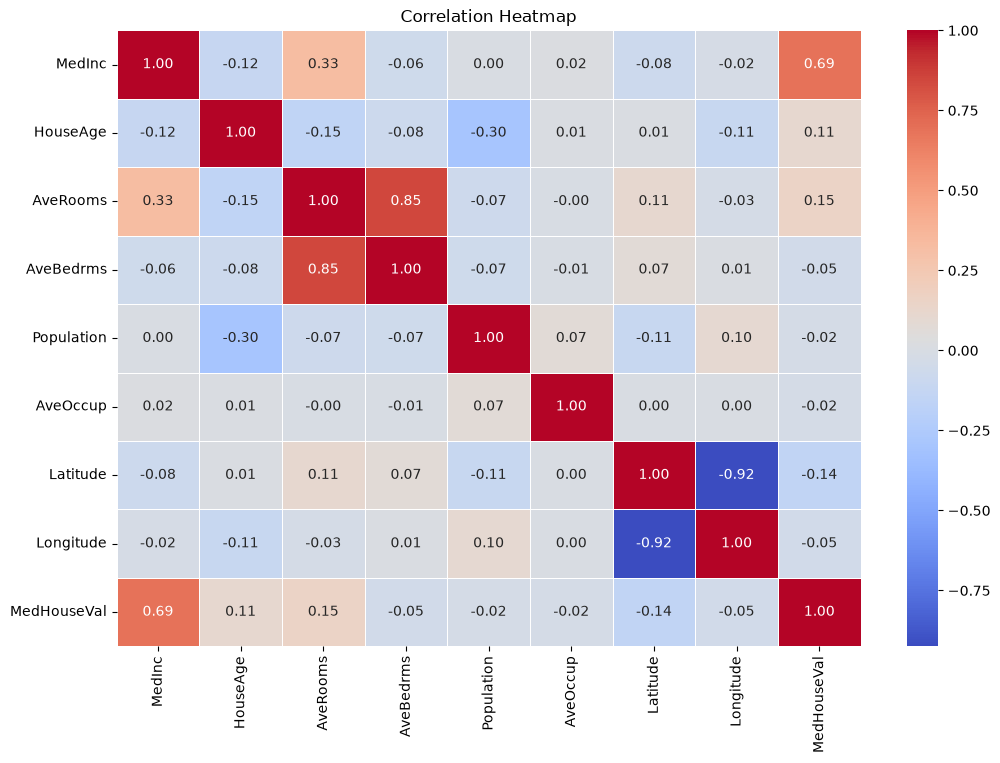

In [15]:
correlation = dataset.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

In [16]:
target_correlation = correlation["MedHouseVal"].sort_values(
    ascending=False
)

print(target_correlation)

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


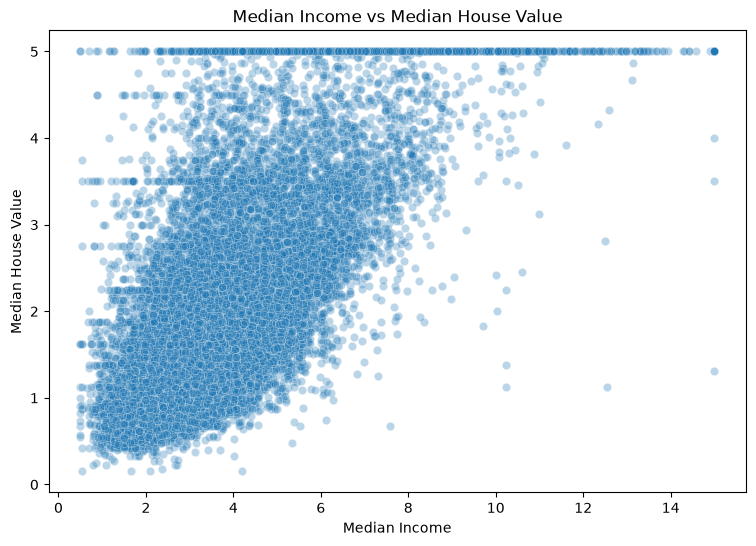

In [17]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=dataset,
    x="MedInc",
    y="MedHouseVal",
    alpha=0.3
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

In [19]:
X = dataset.drop("MedHouseVal", axis=1)

y = dataset["MedHouseVal"]

print("Input Features:", X.shape)
print("Target:", y.shape)

Input Features: (20640, 8)
Target: (20640,)


In [20]:
print("Total Duplicate Rows:", dataset.duplicated().sum())

Total Duplicate Rows: 0


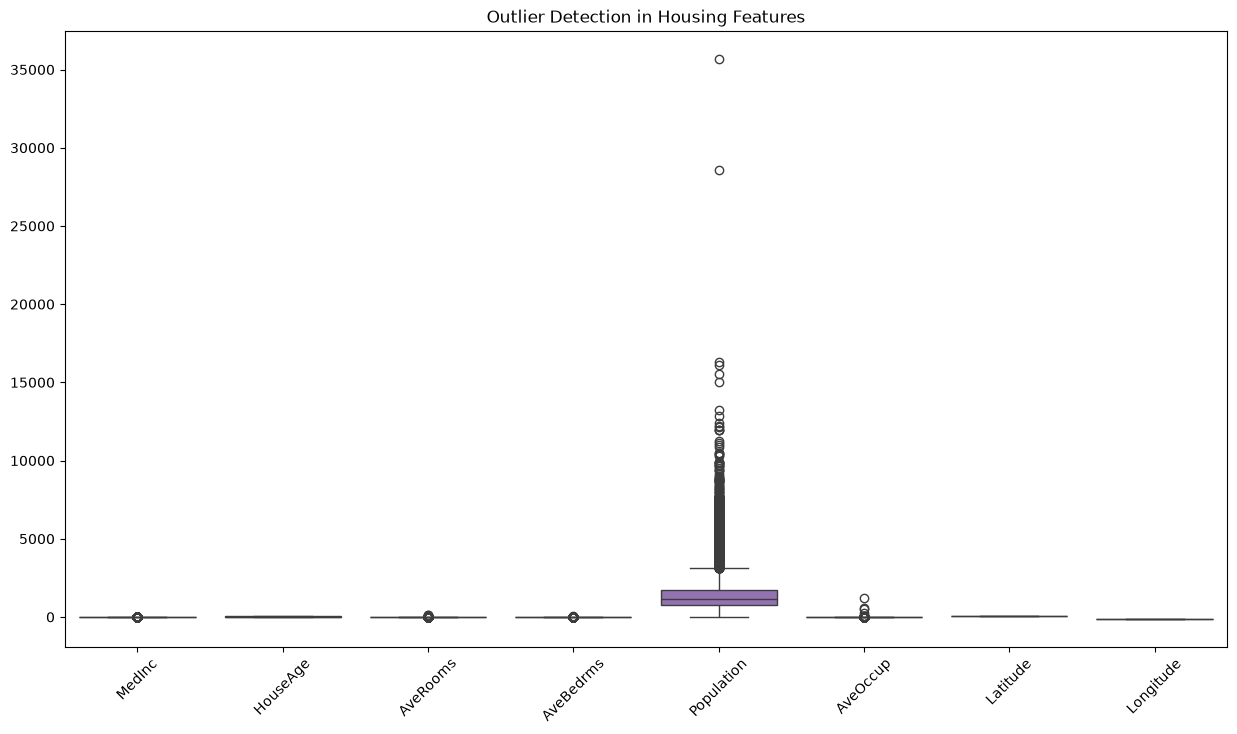

In [21]:
plt.figure(figsize=(15, 8))

sns.boxplot(data=X)

plt.title("Outlier Detection in Housing Features")
plt.xticks(rotation=45)

plt.show()

In [22]:
X = X.copy()

X["RoomsPerHousehold"] = X["AveRooms"] / X["AveOccup"]

X["BedroomsPerRoom"] = X["AveBedrms"] / X["AveRooms"]

print("New Features Created!")

X.head()

New Features Created!


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,RoomsPerHousehold,BedroomsPerRoom
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,2.732919,0.146591
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,2.956685,0.155797
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,2.957661,0.129516
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,2.283154,0.184458
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,2.879646,0.172096


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 10)
Testing Features: (4128, 10)
Training Target: (16512,)
Testing Target: (4128,)


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

preprocessor = Pipeline([
    ("scaler", StandardScaler())
])

X_train_scaled = preprocessor.fit_transform(X_train)

X_test_scaled = preprocessor.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

Training data scaled: (16512, 10)
Testing data scaled: (4128, 10)


In [25]:
print("Final Training Data:", X_train_scaled.shape)
print("Final Testing Data:", X_test_scaled.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Final Training Data: (16512, 10)
Final Testing Data: (4128, 10)

Training target: (16512,)
Testing target: (4128,)


In [26]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [27]:
baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train_scaled, y_train)

baseline_predictions = baseline_model.predict(X_test_scaled)

print("Baseline Model Trained Successfully!")

Baseline Model Trained Successfully!


In [28]:
baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

print("BASELINE MODEL PERFORMANCE")
print("---------------------------")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R2 Score:", baseline_r2)

BASELINE MODEL PERFORMANCE
---------------------------
MAE: 0.9060685490007149
RMSE: 1.1448563543099792
R2 Score: -0.00021908714592466794


In [29]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

linear_predictions = linear_model.predict(X_test_scaled)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [30]:
linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("LINEAR REGRESSION PERFORMANCE")
print("------------------------------")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)

LINEAR REGRESSION PERFORMANCE
------------------------------
MAE: 0.4861644025414969
RMSE: 0.675347242463118
R2 Score: 0.6519453808117215


In [31]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression"],
    "MAE": [baseline_mae, linear_mae],
    "RMSE": [baseline_rmse, linear_rmse],
    "R2 Score": [baseline_r2, linear_r2]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Baseline,0.906069,1.144856,-0.000219
1,Linear Regression,0.486164,0.675347,0.651945


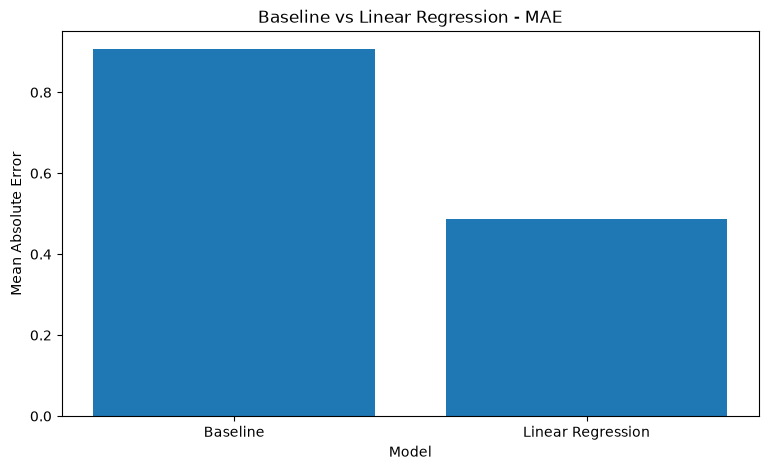

In [32]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["MAE"]
)

plt.title("Baseline vs Linear Regression - MAE")
plt.ylabel("Mean Absolute Error")
plt.xlabel("Model")

plt.show()

In [33]:
from sklearn.ensemble import RandomForestRegressor

In [34]:
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

In [35]:
random_forest_model.fit(X_train_scaled, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [38]:
random_forest_model.fit(X_train_scaled, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [39]:
rf_predictions = random_forest_model.predict(X_test_scaled)

print("Predictions generated successfully!")
print(rf_predictions[:10])

Predictions generated successfully!
[0.50515484 0.83690313 4.95315713 2.50843234 2.23794681 1.67051826
 2.48358745 1.67433108 2.60822746 4.96633756]


In [40]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST PERFORMANCE")
print("-------------------------")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

RANDOM FOREST PERFORMANCE
-------------------------
MAE: 0.3334313803515321
RMSE: 0.5093877085864175
R2 Score: 0.801988660053869


In [42]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

In [44]:
cv_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

In [45]:
cv_results = cross_validate(
    cv_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=-1
)

In [46]:
cv_mae = -cv_results["test_MAE"].mean()
cv_rmse = -cv_results["test_RMSE"].mean()
cv_r2 = cv_results["test_R2"].mean()

print("5-FOLD CROSS-VALIDATION RESULTS")
print("--------------------------------")
print("Average MAE:", cv_mae)
print("Average RMSE:", cv_rmse)
print("Average R2 Score:", cv_r2)

5-FOLD CROSS-VALIDATION RESULTS
--------------------------------
Average MAE: 0.33884011038755957
Average RMSE: 0.5149631566098514
Average R2 Score: 0.8014621719282304


In [47]:
residuals = y_test - rf_predictions

print("First 10 Residuals:")
print(residuals.head(10))

First 10 Residuals:
20046   -0.028155
3024    -0.378903
15663    0.046853
20484   -0.322432
9814     0.542053
13311   -0.083518
7113    -0.501587
7668    -0.099331
18246    0.791773
5723    -0.500338
Name: MedHouseVal, dtype: float64


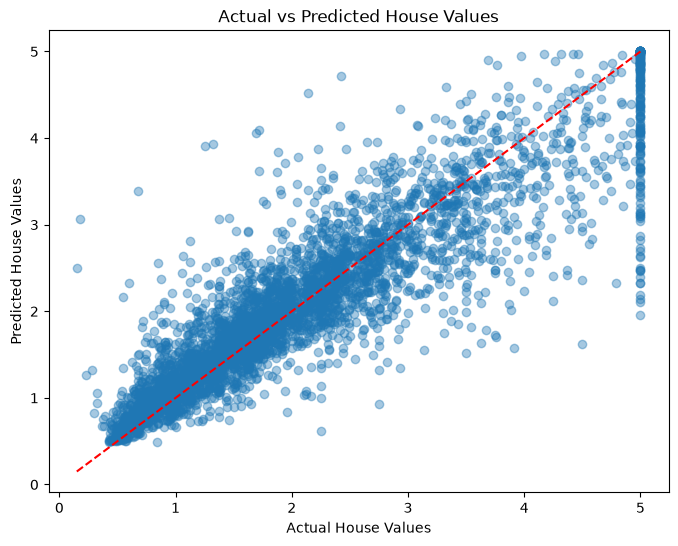

In [48]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_predictions, alpha=0.4)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.show()

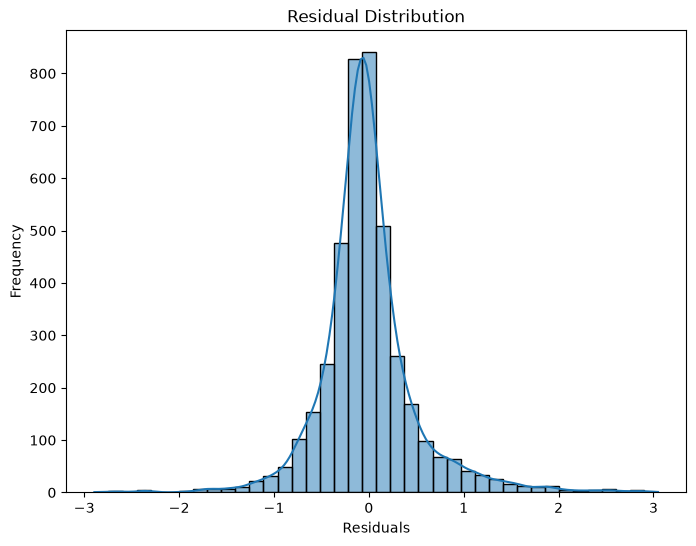

In [49]:
plt.figure(figsize=(8, 6))

sns.histplot(residuals, bins=40, kde=True)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution")

plt.show()

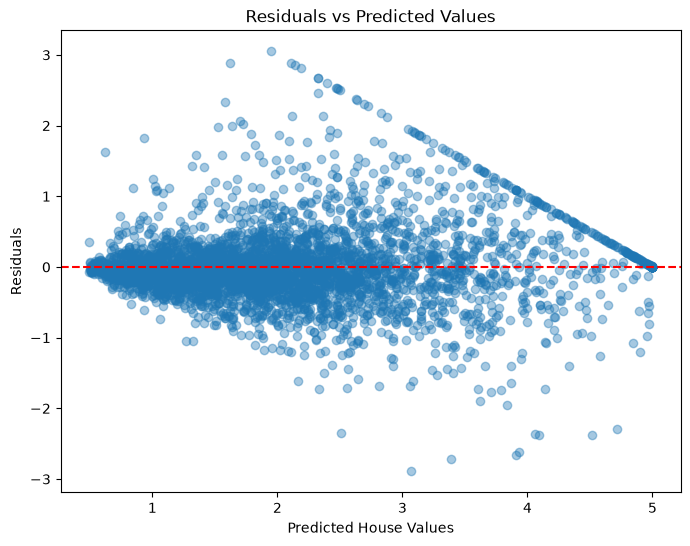

In [50]:
plt.figure(figsize=(8, 6))

plt.scatter(rf_predictions, residuals, alpha=0.4)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.show()

In [51]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

             Feature  Importance
0             MedInc    0.532854
5           AveOccup    0.128711
6           Latitude    0.083219
7          Longitude    0.083080
1           HouseAge    0.050786
9    BedroomsPerRoom    0.027723
4         Population    0.024587
8  RoomsPerHousehold    0.024525
2           AveRooms    0.024067
3          AveBedrms    0.020448


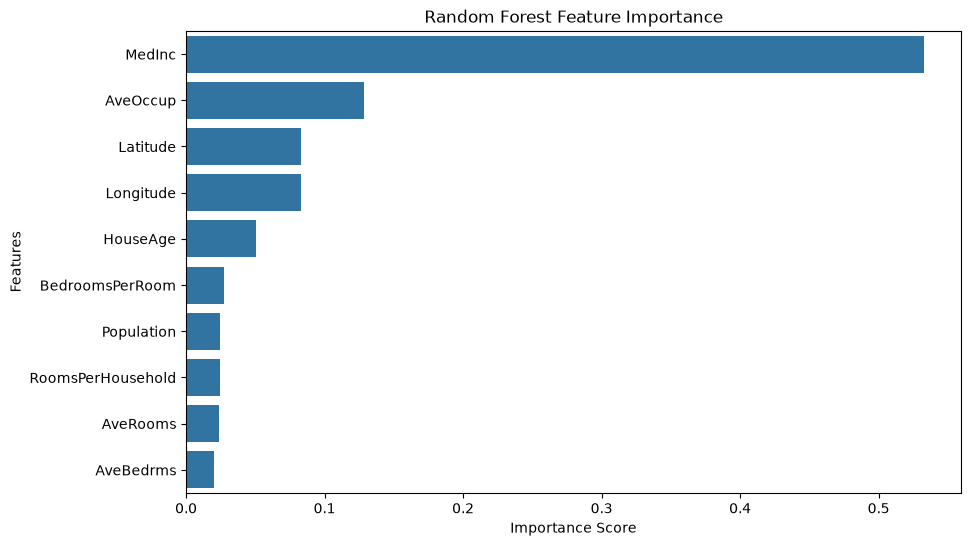

In [52]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

In [53]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression", "Random Forest"],
    "MAE": [baseline_mae, linear_mae, rf_mae],
    "RMSE": [baseline_rmse, linear_rmse, rf_rmse],
    "R2 Score": [baseline_r2, linear_r2, rf_r2]
})

print(comparison)

               Model       MAE      RMSE  R2 Score
0           Baseline  0.906069  1.144856 -0.000219
1  Linear Regression  0.486164  0.675347  0.651945
2      Random Forest  0.333431  0.509388  0.801989


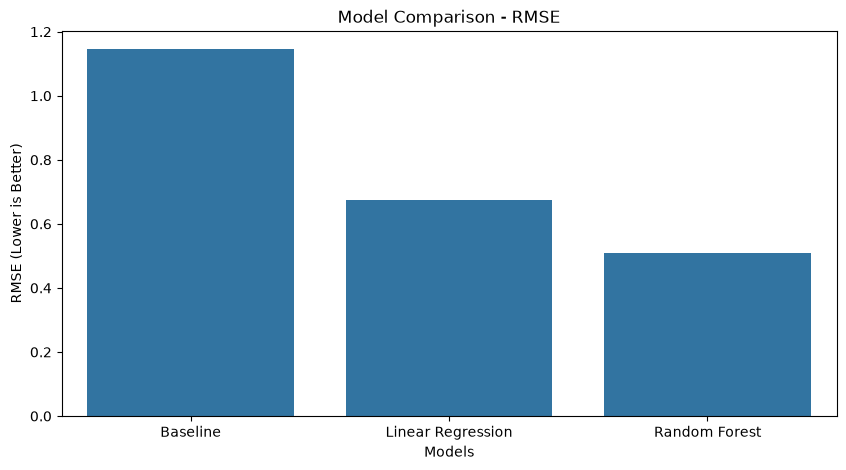

In [54]:
plt.figure(figsize=(10, 5))

sns.barplot(data=comparison, x="Model", y="RMSE")

plt.title("Model Comparison - RMSE")
plt.ylabel("RMSE (Lower is Better)")
plt.xlabel("Models")

plt.show()

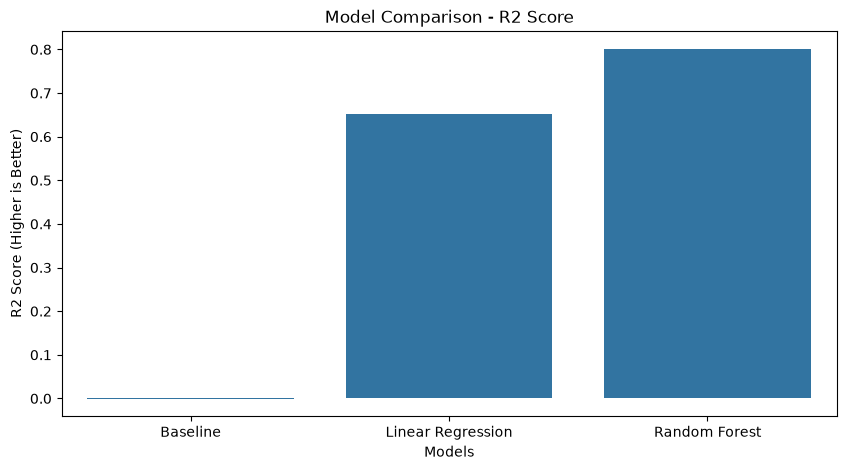

In [55]:
plt.figure(figsize=(10, 5))

sns.barplot(data=comparison, x="Model", y="R2 Score")

plt.title("Model Comparison - R2 Score")
plt.ylabel("R2 Score (Higher is Better)")
plt.xlabel("Models")

plt.show()

In [56]:
comparison

,Model,MAE,RMSE,R2 Score
0,Baseline,0.906069,1.144856,-0.000219
1,Linear Regression,0.486164,0.675347,0.651945
2,Random Forest,0.333431,0.509388,0.801989


In [57]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

In [58]:
final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [59]:
final_predictions = final_model.predict(X_test)

final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_r2 = r2_score(y_test, final_predictions)

print("FINAL MODEL PERFORMANCE")
print("-----------------------")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R2 Score:", final_r2)

FINAL MODEL PERFORMANCE
-----------------------
MAE: 0.3334313803515321
RMSE: 0.5093877085864175
R2 Score: 0.801988660053869


In [60]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(final_model, "models/california_housing_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [61]:
loaded_model = joblib.load("models/california_housing_model.pkl")

test_prediction = loaded_model.predict(X_test.iloc[:5])

print("First 5 predictions:")
print(test_prediction)

First 5 predictions:
[0.50515484 0.83690313 4.95315713 2.50843234 2.23794681]


In [62]:
from sklearn.base import BaseEstimator, TransformerMixin

class FeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        X["RoomsPerHousehold"] = (
            X["AveRooms"] / X["AveOccup"]
        )

        X["BedroomsPerRoom"] = (
            X["AveBedrms"] / X["AveRooms"]
        )

        return X

In [63]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

final_model = Pipeline([
    ("feature_engineering", FeatureEngineer()),
    ("scaler", StandardScaler()),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

In [64]:
X_raw = dataset.drop("MedHouseVal", axis=1)
y = dataset["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42
)

final_model.fit(X_train, y_train)

print("Complete pipeline trained successfully!")

Complete pipeline trained successfully!


In [65]:
final_predictions = final_model.predict(X_test)

final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_r2 = r2_score(y_test, final_predictions)

print("FINAL MODEL PERFORMANCE")
print("-----------------------")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R2 Score:", final_r2)

FINAL MODEL PERFORMANCE
-----------------------
MAE: 0.33343138035153214
RMSE: 0.5093877085864175
R2 Score: 0.801988660053869


In [66]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    final_model,
    "models/california_housing_model.pkl"
)

print("Complete model saved successfully!")

Complete model saved successfully!


In [67]:
loaded_model = joblib.load(
    "models/california_housing_model.pkl"
)

sample_data = X_test.iloc[:5]

predictions = loaded_model.predict(sample_data)

print("Predicted house values:")
print(predictions)

print("\nActual house values:")
print(y_test.iloc[:5].values)

Predicted house values:
[0.50515484 0.83690313 4.95315713 2.50843234 2.23794681]

Actual house values:
[0.477   0.458   5.00001 2.186   2.78   ]


In [68]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions
final_predictions = final_model.predict(X_test)

# Calculate evaluation metrics
final_mae = mean_absolute_error(y_test, final_predictions)

final_rmse = np.sqrt(
    mean_squared_error(y_test, final_predictions)
)

final_r2 = r2_score(y_test, final_predictions)

# Display results
print("FINAL MODEL EVALUATION")
print("----------------------")
print("MAE:", round(final_mae, 4))
print("RMSE:", round(final_rmse, 4))
print("R2 Score:", round(final_r2, 4))

FINAL MODEL EVALUATION
----------------------
MAE: 0.3334
RMSE: 0.5094
R2 Score: 0.802
